# 04 — Unseen Test Evaluation

## Objective

Evaluate the generalization of the AthletiQ player detection models on
completely unseen SportsMOT test data.

Models evaluated:

1. Base Model — YOLOv26m fine-tuned on SportsMOT Football
2. Fine-tuned Model — YOLOv26m further fine-tuned using hard examples

The SportsMOT test set is kept completely untouched.

This notebook is strictly for evaluation:
- No training
- No fine-tuning
- No threshold tuning
- No NMS tuning
- No modification of test data

Since public SportsMOT test ground-truth annotations are not available,
this notebook performs qualitative/generalization analysis on the test set.

Quantitative evaluation on unseen annotated data will be performed separately.

In [1]:
from pathlib import Path
import sys
import os
import json
import random
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO

print("Imports successful")

Imports successful


In [2]:
import torch
import ultralytics

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Ultralytics:", ultralytics.__version__)

Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
PyTorch: 2.14.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Ultralytics: 8.4.138


In [3]:
PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

TEST_DIR = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "benchmarks"
    / "sportsmot"
    / "extracted"
    / "test"
)

BASE_MODEL = (
    PROJECT_ROOT
    / "ai-engine"
    / "models"
    / "yolov26m-sportsmot-football.pt"
)

FINETUNED_MODEL = (
    PROJECT_ROOT
    / "ai-engine"
    / "models"
    / "yolov26m_hard_finetune.pt"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "ai-engine"
    / "notebooks"
    / "runs"
    / "unseen_test"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Test directory:", TEST_DIR)
print("Base model:", BASE_MODEL)
print("Fine-tuned model:", FINETUNED_MODEL)
print("Output directory:", OUTPUT_DIR)

Test directory: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test
Base model: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/yolov26m-sportsmot-football.pt
Fine-tuned model: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/yolov26m_hard_finetune.pt
Output directory: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/runs/unseen_test


In [4]:
print("Test directory exists:", TEST_DIR.exists())

if not TEST_DIR.exists():
    raise FileNotFoundError(f"Test directory not found: {TEST_DIR}")

sequences = sorted([
    p for p in TEST_DIR.iterdir()
    if p.is_dir()
])

print("Number of test sequences:", len(sequences))

for seq in sequences:
    img_dir = seq / "img1"
    image_count = len(list(img_dir.glob("*.jpg"))) if img_dir.exists() else 0
    
    print(f"{seq.name}: {image_count} frames")

Test directory exists: True
Number of test sequences: 150
v_-9kabh1K8UA_c008: 1200 frames
v_-9kabh1K8UA_c009: 2000 frames
v_-9kabh1K8UA_c010: 1802 frames
v_-hhDbvY5aAM_c001: 1496 frames
v_-hhDbvY5aAM_c002: 932 frames
v_-hhDbvY5aAM_c005: 1100 frames
v_-hhDbvY5aAM_c006: 1000 frames
v_-hhDbvY5aAM_c007: 1350 frames
v_-hhDbvY5aAM_c008: 1000 frames
v_-hhDbvY5aAM_c009: 1450 frames
v_-hhDbvY5aAM_c011: 2150 frames
v_-hhDbvY5aAM_c012: 1350 frames
v_-hhDbvY5aAM_c600: 940 frames
v_-hhDbvY5aAM_c602: 1080 frames
v_1UDUODIBSsc_c001: 1846 frames
v_1UDUODIBSsc_c004: 1150 frames
v_1UDUODIBSsc_c015: 1084 frames
v_1UDUODIBSsc_c037: 1424 frames
v_1UDUODIBSsc_c055: 1610 frames
v_1UDUODIBSsc_c056: 1150 frames
v_1UDUODIBSsc_c063: 950 frames
v_1UDUODIBSsc_c067: 1728 frames
v_1UDUODIBSsc_c090: 1050 frames
v_1UDUODIBSsc_c103: 2124 frames
v_1UDUODIBSsc_c111: 1200 frames
v_1UDUODIBSsc_c113: 1742 frames
v_1UDUODIBSsc_c601: 1060 frames
v_1UDUODIBSsc_c602: 1120 frames
v_1UDUODIBSsc_c603: 920 frames
v_1UDUODIBSsc_c606

In [5]:
from pathlib import Path

# Project paths
PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

SPORTSMOT_ROOT = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "benchmarks"
    / "sportsmot"
)

TEST_DIR = SPORTSMOT_ROOT / "extracted" / "test"

FOOTBALL_LIST = SPORTSMOT_ROOT / "football.txt"
BASKETBALL_LIST = SPORTSMOT_ROOT / "basketball.txt"
VOLLEYBALL_LIST = SPORTSMOT_ROOT / "volleyball.txt"

print("Test directory:", TEST_DIR)
print("Exists:", TEST_DIR.exists())

print("\nSplit files:")
print("Football:", FOOTBALL_LIST.exists())
print("Basketball:", BASKETBALL_LIST.exists())
print("Volleyball:", VOLLEYBALL_LIST.exists())

Test directory: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test
Exists: True

Split files:
Football: True
Basketball: True
Volleyball: True


In [6]:
def read_sequence_list(path):
    with open(path, "r", encoding="utf-8") as f:
        return {
            line.strip()
            for line in f
            if line.strip()
        }

football_sequences = read_sequence_list(FOOTBALL_LIST)
basketball_sequences = read_sequence_list(BASKETBALL_LIST)
volleyball_sequences = read_sequence_list(VOLLEYBALL_LIST)

print("Football listed:", len(football_sequences))
print("Basketball listed:", len(basketball_sequences))
print("Volleyball listed:", len(volleyball_sequences))

Football listed: 80
Basketball listed: 80
Volleyball listed: 80


In [7]:
extracted_sequences = {
    p.name
    for p in TEST_DIR.iterdir()
    if p.is_dir()
}

print("Extracted sequences:", len(extracted_sequences))

print("\nFootball extracted:",
      len(extracted_sequences & football_sequences))

print("Basketball extracted:",
      len(extracted_sequences & basketball_sequences))

print("Volleyball extracted:",
      len(extracted_sequences & volleyball_sequences))

print("\nUnknown sequences:",
      len(
          extracted_sequences
          - football_sequences
          - basketball_sequences
          - volleyball_sequences
      ))

Extracted sequences: 150

Football extracted: 50
Basketball extracted: 50
Volleyball extracted: 50

Unknown sequences: 0


In [8]:
from pathlib import Path

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

SPORTSMOT_FOOTBALL = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "benchmarks"
    / "sportsmot"
)

SPORTSMOT_BASKETBALL = (
    PROJECT_ROOT
    / "datasets"
    / "basketball"
    / "benchmarks"
    / "sportsmot"
)

FOOTBALL_TEST = SPORTSMOT_FOOTBALL / "extracted" / "test"
BASKETBALL_TEST = SPORTSMOT_BASKETBALL / "extracted" / "test"

BASKETBALL_TEST.mkdir(parents=True, exist_ok=True)

print("Football test:")
print(FOOTBALL_TEST)

print("\nBasketball test:")
print(BASKETBALL_TEST)

print("\nBasketball directory exists:",
      BASKETBALL_TEST.exists())

Football test:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test

Basketball test:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/basketball/benchmarks/sportsmot/extracted/test

Basketball directory exists: True


In [9]:
def read_sequence_list(path):
    with open(path, "r", encoding="utf-8") as f:
        return {
            line.strip()
            for line in f
            if line.strip()
        }

football_sequences = read_sequence_list(
    SPORTSMOT_FOOTBALL / "football.txt"
)

basketball_sequences = read_sequence_list(
    SPORTSMOT_FOOTBALL / "basketball.txt"
)

volleyball_sequences = read_sequence_list(
    SPORTSMOT_FOOTBALL / "volleyball.txt"
)

extracted_sequences = {
    p.name
    for p in FOOTBALL_TEST.iterdir()
    if p.is_dir()
}

print("Football:", len(extracted_sequences & football_sequences))
print("Basketball:", len(extracted_sequences & basketball_sequences))
print("Volleyball:", len(extracted_sequences & volleyball_sequences))

Football: 50
Basketball: 50
Volleyball: 50


In [10]:
import shutil
from pathlib import Path

# Move only sequences identified as basketball
basketball_to_move = sorted(
    extracted_sequences & basketball_sequences
)

print(f"Basketball sequences to move: {len(basketball_to_move)}")

for seq_name in basketball_to_move:
    source = FOOTBALL_TEST / seq_name
    destination = BASKETBALL_TEST / seq_name

    if destination.exists():
        print(f"SKIP — already exists: {seq_name}")
        continue

    shutil.move(str(source), str(destination))
    print(f"Moved: {seq_name}")

print("\nBasketball transfer complete.")

Basketball sequences to move: 50
Moved: v_-9kabh1K8UA_c008
Moved: v_-9kabh1K8UA_c009
Moved: v_-9kabh1K8UA_c010
Moved: v_2BhBRkkAqbQ_c002
Moved: v_42VrMbd68Zg_c003
Moved: v_42VrMbd68Zg_c004
Moved: v_42VrMbd68Zg_c011
Moved: v_42VrMbd68Zg_c012
Moved: v_6OLC1-bhioc_c001
Moved: v_6OLC1-bhioc_c003
Moved: v_6OLC1-bhioc_c005
Moved: v_6OLC1-bhioc_c007
Moved: v_6OLC1-bhioc_c008
Moved: v_6OLC1-bhioc_c009
Moved: v_6OLC1-bhioc_c011
Moved: v_6OLC1-bhioc_c012
Moved: v_6OLC1-bhioc_c013
Moved: v_6OLC1-bhioc_c014
Moved: v_6oTxfzKdG6Q_c004
Moved: v_6oTxfzKdG6Q_c015
Moved: v_7FTsO8S3h88_c001
Moved: v_7FTsO8S3h88_c004
Moved: v_7FTsO8S3h88_c005
Moved: v_7FTsO8S3h88_c006
Moved: v_7FTsO8S3h88_c007
Moved: v_7FTsO8S3h88_c008
Moved: v_82WN8C8qJmI_c002
Moved: v_82WN8C8qJmI_c003
Moved: v_82WN8C8qJmI_c004
Moved: v_82WN8C8qJmI_c005
Moved: v_82WN8C8qJmI_c014
Moved: v_A4OJhlI6hgc_c001
Moved: v_A4OJhlI6hgc_c002
Moved: v_A4OJhlI6hgc_c003
Moved: v_A4OJhlI6hgc_c005
Moved: v_A4OJhlI6hgc_c601
Moved: v_BdD9xu0E2H4_c003
Moved

In [11]:
# Verify Football test
football_remaining = {
    p.name for p in FOOTBALL_TEST.iterdir()
    if p.is_dir()
}

# Verify Basketball test
basketball_now = {
    p.name for p in BASKETBALL_TEST.iterdir()
    if p.is_dir()
}

print("Football directory now contains:", len(football_remaining))
print("Basketball directory now contains:", len(basketball_now))

print("\nFootball sequences remaining:")
print(" ", len(football_remaining & football_sequences))

print("Basketball sequences transferred:")
print(" ", len(basketball_now & basketball_sequences))

print("Unexpected sequences remaining in football/test:")
print(
    football_remaining
    - football_sequences
    - volleyball_sequences
)

Football directory now contains: 100
Basketball directory now contains: 50

Football sequences remaining:
  50
Basketball sequences transferred:
  50
Unexpected sequences remaining in football/test:
set()


In [12]:
import shutil

# Recalculate what is currently in football/test
football_remaining = {
    p.name for p in FOOTBALL_TEST.iterdir()
    if p.is_dir()
}

volleyball_to_delete = sorted(
    football_remaining & volleyball_sequences
)

print(f"Volleyball sequences found: {len(volleyball_to_delete)}")

# Safety check
assert len(volleyball_to_delete) == 50, (
    f"Expected 50 volleyball sequences, found {len(volleyball_to_delete)}"
)

# Delete ONLY volleyball sequences
for seq_name in volleyball_to_delete:
    seq_path = FOOTBALL_TEST / seq_name
    shutil.rmtree(seq_path)

print("\nDeleted 50 Volleyball sequences.")

Volleyball sequences found: 50

Deleted 50 Volleyball sequences.


In [13]:
football_final = {
    p.name for p in FOOTBALL_TEST.iterdir()
    if p.is_dir()
}

basketball_final = {
    p.name for p in BASKETBALL_TEST.iterdir()
    if p.is_dir()
}

print("========== FINAL DATASET CHECK ==========")
print(f"Football test sequences   : {len(football_final)}")
print(f"Basketball test sequences : {len(basketball_final)}")

print("\nFootball:")
print(f"  Football sequences : {len(football_final & football_sequences)}")
print(f"  Volleyball left    : {len(football_final & volleyball_sequences)}")
print(f"  Basketball left    : {len(football_final & basketball_sequences)}")

print("\nBasketball:")
print(f"  Basketball sequences : {len(basketball_final & basketball_sequences)}")

print("\nUnexpected football/test sequences:")
print(football_final - football_sequences)

print("\nUnexpected basketball/test sequences:")
print(basketball_final - basketball_sequences)

========== FINAL DATASET CHECK ==========
Football test sequences   : 50
Basketball test sequences : 50

Football:
  Football sequences : 50
  Volleyball left    : 0
  Basketball left    : 0

Basketball:
  Basketball sequences : 50

Unexpected football/test sequences:
set()

Unexpected basketball/test sequences:
set()


In [14]:
# ============================================================
# VERIFY SPORTS MOT TEST STRUCTURE
# ============================================================

def verify_test_structure(test_dir, sport_name):
    test_dir = Path(test_dir)

    sequences = sorted([
        p for p in test_dir.iterdir()
        if p.is_dir()
    ])

    print(f"\n{'='*60}")
    print(f"{sport_name.upper()} TEST DATASET")
    print(f"{'='*60}")
    print(f"Sequences: {len(sequences)}")

    missing_img1 = []
    missing_seqinfo = []
    gt_present = []

    for seq in sequences:
        if not (seq / "img1").is_dir():
            missing_img1.append(seq.name)

        if not (seq / "seqinfo.ini").is_file():
            missing_seqinfo.append(seq.name)

        if (seq / "gt").exists():
            gt_present.append(seq.name)

    print(f"Missing img1/:      {len(missing_img1)}")
    print(f"Missing seqinfo.ini: {len(missing_seqinfo)}")
    print(f"GT directories:      {len(gt_present)}")

    if missing_img1:
        print("\nMissing img1:")
        print(missing_img1)

    if missing_seqinfo:
        print("\nMissing seqinfo.ini:")
        print(missing_seqinfo)

    if gt_present:
        print("\nGT directories found:")
        print(gt_present)

    return sequences


football_test_sequences = verify_test_structure(
    FOOTBALL_TEST,
    "Football"
)

basketball_test_sequences = verify_test_structure(
    BASKETBALL_TEST,
    "Basketball"
)


FOOTBALL TEST DATASET
Sequences: 50
Missing img1/:      0
Missing seqinfo.ini: 0
GT directories:      0

BASKETBALL TEST DATASET
Sequences: 50
Missing img1/:      0
Missing seqinfo.ini: 0
GT directories:      0


In [15]:
from pathlib import Path

DATASETS_DIR = Path("/mnt/d/My Projects/AthletiQ/AthletiQ/datasets")

metadata_files = list(DATASETS_DIR.rglob("._test"))

print(f"Found {len(metadata_files)} '._test' files:\n")

for file in metadata_files:
    print(file)

Found 1 '._test' files:

/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/._test


In [16]:
for file in metadata_files:
    if file.name == "._test" and file.is_file():
        file.unlink()
        print(f"Deleted: {file}")

print("\nCleanup complete.")

Deleted: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/._test

Cleanup complete.


In [17]:
remaining_metadata = list(DATASETS_DIR.rglob("._test"))

print(f"Remaining '._test' files: {len(remaining_metadata)}")

if remaining_metadata:
    for file in remaining_metadata:
        print(file)
else:
    print("No '._test' files remain. ✅")

Remaining '._test' files: 0
No '._test' files remain. ✅


In [18]:
from pathlib import Path
import random
import json
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO

In [19]:
import torch
import ultralytics

print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())
print("Ultralytics     :", ultralytics.__version__)

if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))
    print("CUDA version    :", torch.version.cuda)

PyTorch version : 2.14.0+cu130
CUDA available  : True
Ultralytics     : 8.4.138
GPU             : NVIDIA GeForce RTX 3050 6GB Laptop GPU
CUDA version    : 13.0


In [26]:
PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

FOOTBALL_TEST = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "benchmarks"
    / "sportsmot"
    / "extracted"
    / "test"
)

BASKETBALL_TEST = (
    PROJECT_ROOT
    / "datasets"
    / "basketball"
    / "benchmarks"
    / "sportsmot"
    / "extracted"
    / "test"
)

MODEL_DIR = PROJECT_ROOT / "ai-engine" / "models"

BASE_MODEL_PATH = MODEL_DIR / "yolo11n.pt"

FINETUNED_MODEL_PATH = (
    MODEL_DIR / "yolov26m-sportsmot-football.pt"
)

HARD_FINETUNED_MODEL_PATH = (
    MODEL_DIR / "yolov26m_hard_finetune.pt"
)

print("Project root:", PROJECT_ROOT)
print("Football test:", FOOTBALL_TEST)
print("Basketball test:", BASKETBALL_TEST)

print("\nModels:")
print("Base:", BASE_MODEL_PATH)
print("Fine-tuned:", FINETUNED_MODEL_PATH)
print("Hard fine-tuned:", HARD_FINETUNED_MODEL_PATH)

Project root: /mnt/d/My Projects/AthletiQ/AthletiQ
Football test: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test
Basketball test: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/basketball/benchmarks/sportsmot/extracted/test

Models:
Base: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/yolo11n.pt
Fine-tuned: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/yolov26m-sportsmot-football.pt
Hard fine-tuned: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/yolov26m_hard_finetune.pt


In [27]:
paths_to_check = {
    "Project root": PROJECT_ROOT,
    "Football test": FOOTBALL_TEST,
    "Basketball test": BASKETBALL_TEST,
    "Base YOLO11n": BASE_MODEL_PATH,
    "SportsMOT fine-tuned": FINETUNED_MODEL_PATH,
    "Hard fine-tuned": HARD_FINETUNED_MODEL_PATH,
}

for name, path in paths_to_check.items():
    print(f"{name:25} : {'OK' if path.exists() else 'MISSING'}")

Project root              : OK
Football test             : OK
Basketball test           : OK
Base YOLO11n              : OK
SportsMOT fine-tuned      : OK
Hard fine-tuned           : OK


In [28]:
def get_sequences(test_dir):
    return sorted([
        p for p in Path(test_dir).iterdir()
        if p.is_dir()
    ])


football_sequences_test = get_sequences(FOOTBALL_TEST)
basketball_sequences_test = get_sequences(BASKETBALL_TEST)

print("Football test sequences   :", len(football_sequences_test))
print("Basketball test sequences :", len(basketball_sequences_test))

assert len(football_sequences_test) == 50
assert len(basketball_sequences_test) == 50

print("\nDataset verification: PASS ✅")

Football test sequences   : 50
Basketball test sequences : 50

Dataset verification: PASS ✅


In [29]:
sample_sequence = football_sequences_test[0]

print("Sequence:", sample_sequence.name)
print()

for item in sorted(sample_sequence.iterdir()):
    print(item.name)

Sequence: v_-hhDbvY5aAM_c001

._img1
._seqinfo.ini
img1
seqinfo.ini


In [30]:
image_dir = sample_sequence / "img1"

image_files = sorted(
    image_dir.glob("*.jpg")
)

print("Number of frames:", len(image_files))
print("First frame:", image_files[0])
print("Last frame :", image_files[-1])

Number of frames: 1496
First frame: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/v_-hhDbvY5aAM_c001/img1/._000001.jpg
Last frame : /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/v_-hhDbvY5aAM_c001/img1/000748.jpg


In [31]:
from pathlib import Path

FOOTBALL_TEST = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "datasets/football/benchmarks/sportsmot/extracted/test"
)

BASKETBALL_TEST = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "datasets/basketball/benchmarks/sportsmot/extracted/test"
)

football_metadata = [
    p for p in FOOTBALL_TEST.rglob("._*")
    if p.is_file()
]

basketball_metadata = [
    p for p in BASKETBALL_TEST.rglob("._*")
    if p.is_file()
]

print("Football ._* files   :", len(football_metadata))
print("Basketball ._* files :", len(basketball_metadata))

print("\nSample Football files:")
for p in football_metadata[:10]:
    print(p)

print("\nSample Basketball files:")
for p in basketball_metadata[:10]:
    print(p)

Football ._* files   : 33993
Basketball ._* files : 42794

Sample Football files:
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/._.DS_Store
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/._v_-9kabh1K8UA_c008
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/._v_-9kabh1K8UA_c009
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/._v_-9kabh1K8UA_c010
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/._v_-hhDbvY5aAM_c001
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/._v_-hhDbvY5aAM_c002
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/._v_-hhDbvY5aAM_c005
/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/._v_-hhDbvY5aAM_c006
/mnt/d/My Projects/AthletiQ/Ath

In [32]:
metadata_files = football_metadata + basketball_metadata

for file in metadata_files:
    file.unlink()

print(f"Deleted {len(metadata_files)} AppleDouble metadata files. ✅")

Deleted 76787 AppleDouble metadata files. ✅


In [33]:
sample_sequence = football_sequences_test[0]

image_dir = sample_sequence / "img1"

image_files = sorted(
    p for p in image_dir.glob("*.jpg")
    if not p.name.startswith("._")
)

print("Sequence:", sample_sequence.name)
print("Number of real frames:", len(image_files))
print("First frame:", image_files[0])
print("Last frame :", image_files[-1])

Sequence: v_-hhDbvY5aAM_c001
Number of real frames: 748
First frame: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/v_-hhDbvY5aAM_c001/img1/000001.jpg
Last frame : /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/v_-hhDbvY5aAM_c001/img1/000748.jpg


In [34]:
import torch
from ultralytics import YOLO

base_model = YOLO(str(BASE_MODEL_PATH))
finetuned_model = YOLO(str(FINETUNED_MODEL_PATH))

print("Base model loaded successfully.")
print("Fine-tuned model loaded successfully.")

Base model loaded successfully.
Fine-tuned model loaded successfully.


In [35]:
print("Base model classes:")
print(base_model.names)

print("\nFine-tuned model classes:")
print(finetuned_model.names)

Base model classes:
{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell

In [36]:
def get_real_frames(sequence_dir):
    image_dir = Path(sequence_dir) / "img1"

    return sorted([
        p for p in image_dir.glob("*.jpg")
        if not p.name.startswith("._")
    ])


# Test on the sequence we just inspected
sample_frames = get_real_frames(football_sequences_test[0])

print("Sequence:", football_sequences_test[0].name)
print("Real frames:", len(sample_frames))
print("First:", sample_frames[0].name)
print("Last :", sample_frames[-1].name)

Sequence: v_-hhDbvY5aAM_c001
Real frames: 748
First: 000001.jpg
Last : 000748.jpg


In [37]:
import random

RANDOM_SEED = 42
FRAMES_PER_SEQUENCE = 5

random.seed(RANDOM_SEED)


def sample_test_frames(sequence_dirs, frames_per_sequence=5):
    samples = []

    for seq_dir in sequence_dirs:

        frames = get_real_frames(seq_dir)

        if len(frames) == 0:
            print(f"WARNING: no frames found in {seq_dir.name}")
            continue

        n = min(frames_per_sequence, len(frames))

        selected = random.sample(frames, n)

        for frame_path in selected:
            samples.append({
                "sequence": seq_dir.name,
                "frame_path": frame_path
            })

    return samples


football_samples = sample_test_frames(
    football_sequences_test,
    FRAMES_PER_SEQUENCE
)

basketball_samples = sample_test_frames(
    basketball_sequences_test,
    FRAMES_PER_SEQUENCE
)

print("Football sampled frames   :", len(football_samples))
print("Basketball sampled frames :", len(basketball_samples))
print("Total sampled frames      :", 
      len(football_samples) + len(basketball_samples))

Football sampled frames   : 250
Basketball sampled frames : 250
Total sampled frames      : 500


Frame: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/v_-hhDbvY5aAM_c001/img1/000655.jpg
Shape: (720, 1280, 3)


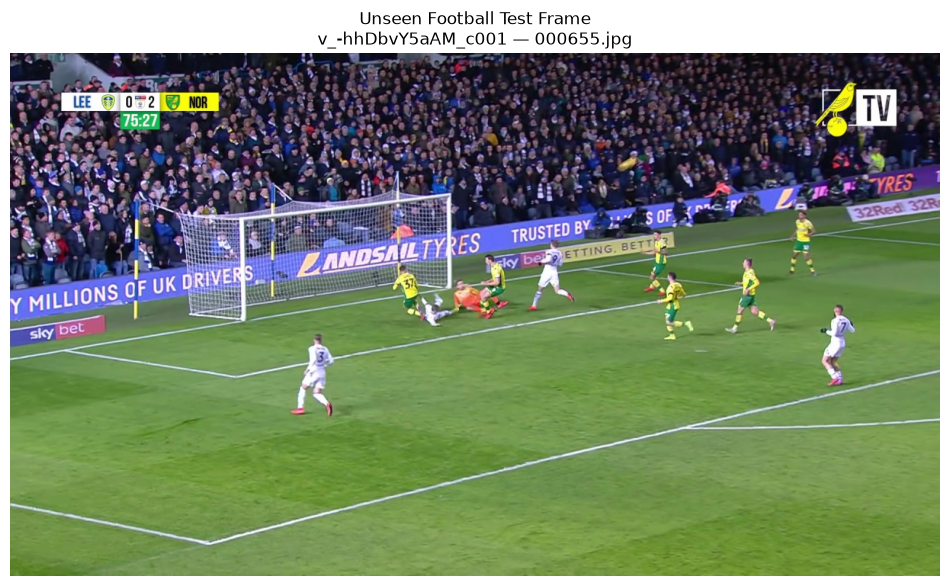

In [38]:
test_frame = football_samples[0]["frame_path"]

image = cv2.imread(str(test_frame))

print("Frame:", test_frame)
print("Shape:", image.shape)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 7))
plt.imshow(image_rgb)
plt.title(
    f"Unseen Football Test Frame\n"
    f"{football_samples[0]['sequence']} — {test_frame.name}"
)
plt.axis("off")
plt.show()

In [39]:
def run_detection(model, frame_path, conf=0.25, imgsz=1280):

    results = model.predict(
        source=str(frame_path),
        conf=conf,
        imgsz=imgsz,
        device=0 if torch.cuda.is_available() else "cpu",
        verbose=False
    )

    result = results[0]

    if result.boxes is None or len(result.boxes) == 0:
        return {
            "boxes": np.empty((0, 4)),
            "confidences": np.array([]),
            "count": 0
        }

    boxes = result.boxes.xyxy.cpu().numpy()
    confidences = result.boxes.conf.cpu().numpy()

    return {
        "boxes": boxes,
        "confidences": confidences,
        "count": len(boxes)
    }


base_result = run_detection(
    base_model,
    test_frame
)

finetuned_result = run_detection(
    finetuned_model,
    test_frame
)

print("Frame:", test_frame.name)
print()
print("YOLO11n detections      :", base_result["count"])
print("Fine-tuned detections   :", finetuned_result["count"])

Frame: 000655.jpg

YOLO11n detections      : 19
Fine-tuned detections   : 10


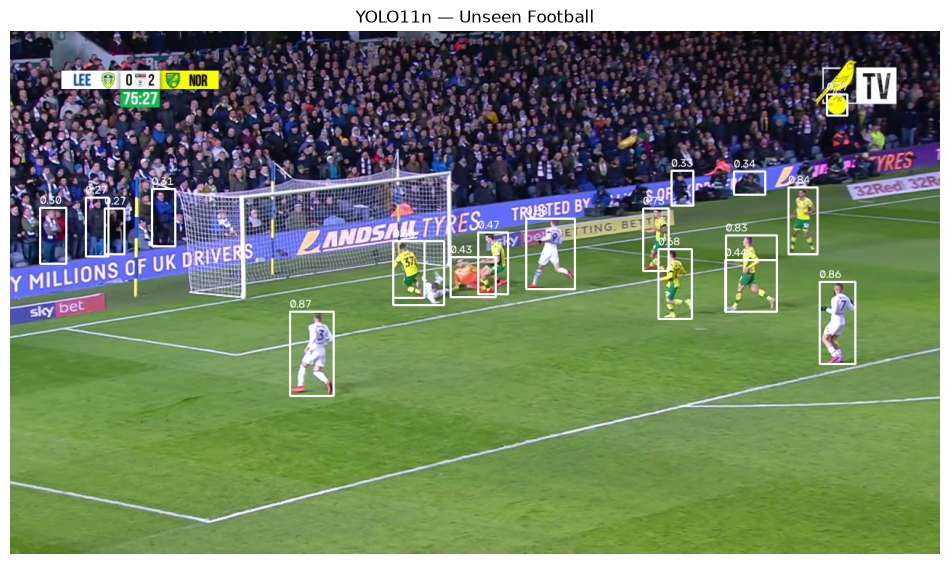

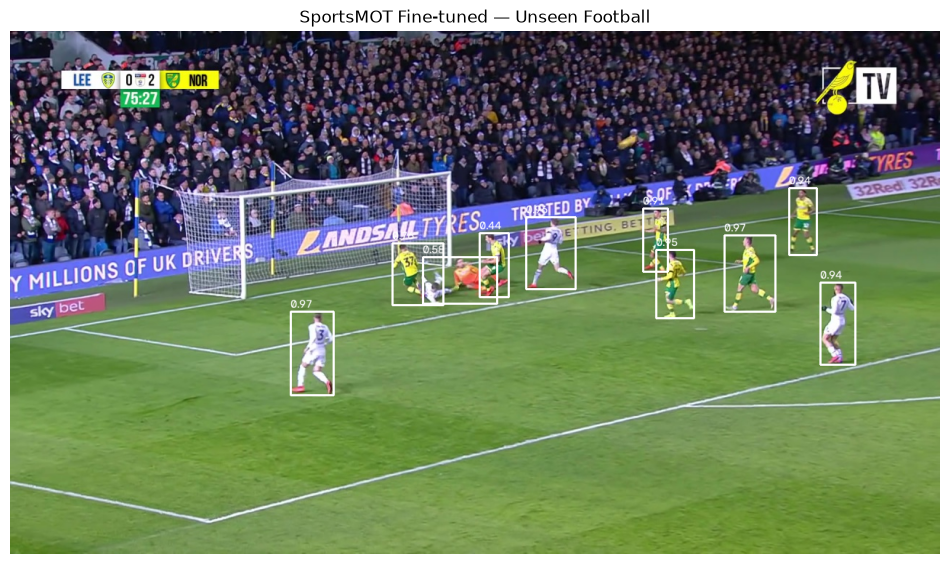

In [40]:
def visualize_detection(
    frame_path,
    result,
    title
):
    image = cv2.imread(str(frame_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    for box, conf in zip(
        result["boxes"],
        result["confidences"]
    ):
        x1, y1, x2, y2 = map(int, box)

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (255, 255, 255),
            2
        )

        cv2.putText(
            image,
            f"{conf:.2f}",
            (x1, max(y1 - 5, 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 255, 255),
            1
        )

    plt.figure(figsize=(12, 7))
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")
    plt.show()


visualize_detection(
    test_frame,
    base_result,
    "YOLO11n — Unseen Football"
)

visualize_detection(
    test_frame,
    finetuned_result,
    "SportsMOT Fine-tuned — Unseen Football"
)

In [41]:
# Select the first basketball sequence
basketball_sample_sequence = basketball_sequences_test[0]

basketball_frames = get_real_frames(
    basketball_sample_sequence
)

print("Sequence:", basketball_sample_sequence.name)
print("Real frames:", len(basketball_frames))

# Select a reproducible middle frame
basketball_test_frame = basketball_frames[
    len(basketball_frames) // 2
]

print("Test frame:", basketball_test_frame)

Sequence: v_-9kabh1K8UA_c008
Real frames: 600
Test frame: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/basketball/benchmarks/sportsmot/extracted/test/v_-9kabh1K8UA_c008/img1/000301.jpg


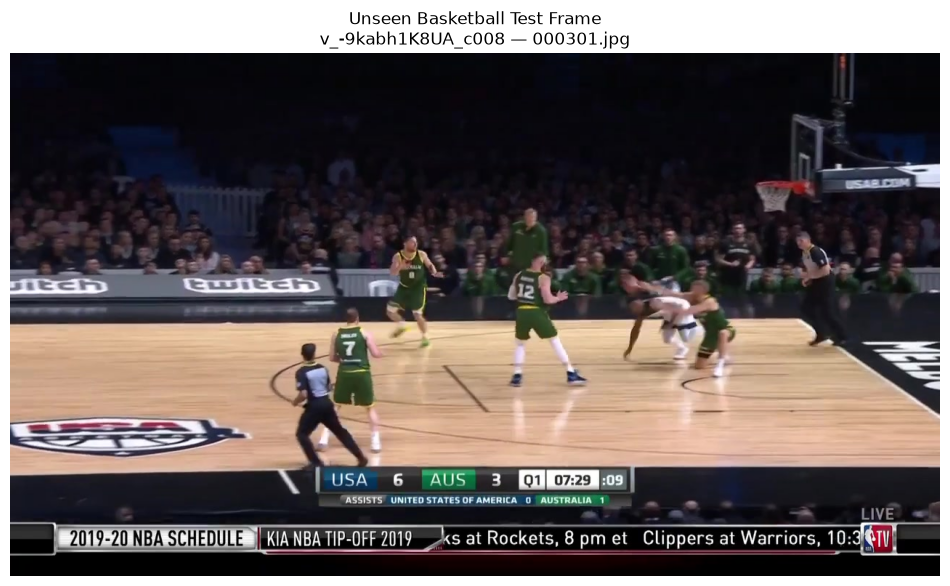

In [42]:
image = cv2.imread(str(basketball_test_frame))
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 7))
plt.imshow(image_rgb)
plt.title(
    f"Unseen Basketball Test Frame\n"
    f"{basketball_sample_sequence.name} — "
    f"{basketball_test_frame.name}"
)
plt.axis("off")
plt.show()

In [43]:
basketball_base_result = run_detection(
    base_model,
    basketball_test_frame
)

basketball_finetuned_result = run_detection(
    finetuned_model,
    basketball_test_frame
)

print("Basketball frame:", basketball_test_frame.name)
print()
print("YOLO11n detections    :", basketball_base_result["count"])
print(
    "Fine-tuned detections :",
    basketball_finetuned_result["count"]
)

Basketball frame: 000301.jpg

YOLO11n detections    : 15
Fine-tuned detections : 0


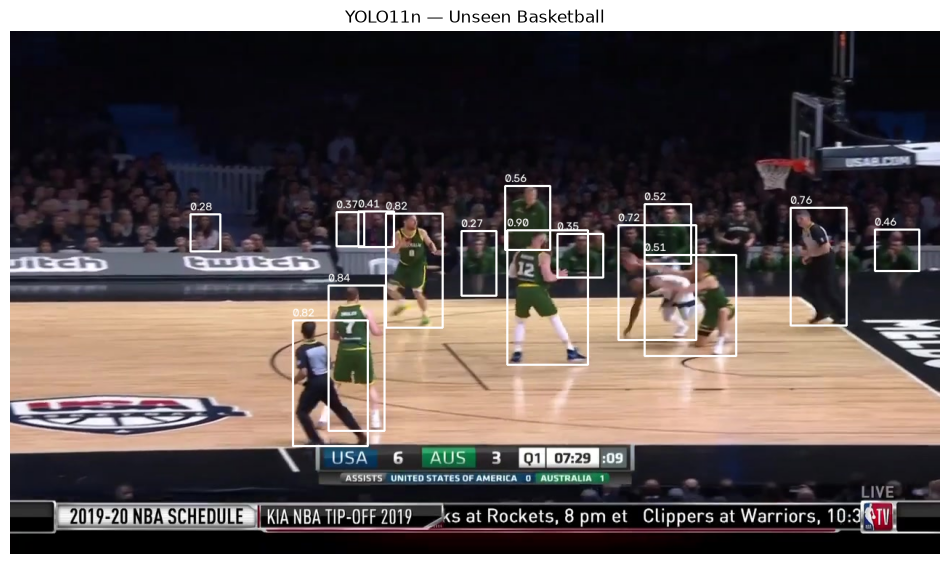

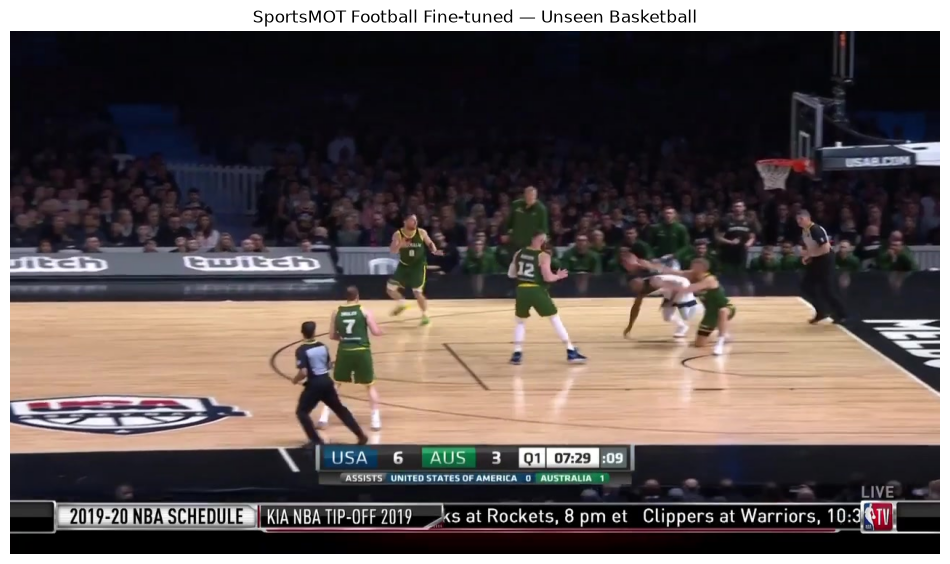

In [44]:
visualize_detection(
    basketball_test_frame,
    basketball_base_result,
    "YOLO11n — Unseen Basketball"
)

visualize_detection(
    basketball_test_frame,
    basketball_finetuned_result,
    "SportsMOT Football Fine-tuned — Unseen Basketball"
)

In [45]:
print("Basketball frame:", basketball_test_frame)

print("\nYOLO11n detections:")
print(basketball_base_result["count"])

print("\nFootball fine-tuned model detections:")
print(basketball_finetuned_result["count"])

Basketball frame: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/basketball/benchmarks/sportsmot/extracted/test/v_-9kabh1K8UA_c008/img1/000301.jpg

YOLO11n detections:
15

Football fine-tuned model detections:
0


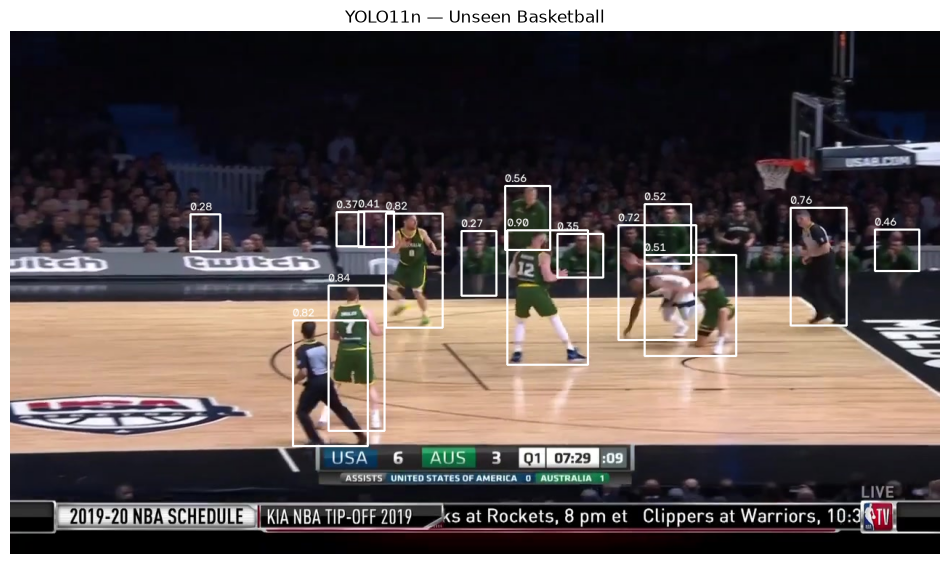

In [46]:
visualize_detection(
    basketball_test_frame,
    basketball_base_result,
    "YOLO11n — Unseen Basketball"
)

In [47]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch

from ultralytics import YOLO

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

FOOTBALL_TEST = (
    PROJECT_ROOT
    / "datasets"
    / "football"
    / "benchmarks"
    / "sportsmot"
    / "extracted"
    / "test"
)

MODEL_PATH = (
    PROJECT_ROOT
    / "ai-engine"
    / "models"
    / "yolov26m-sportsmot-football.pt"
)

finetuned_model = YOLO(str(MODEL_PATH))

print("Model:", MODEL_PATH)
print("Loaded successfully.")
print("Classes:", finetuned_model.names)

Model: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/yolov26m-sportsmot-football.pt
Loaded successfully.
Classes: {0: 'player'}


In [49]:
def get_real_frames(sequence_dir):
    image_dir = Path(sequence_dir) / "img1"

    return sorted([
        p for p in image_dir.glob("*.jpg")
        if not p.name.startswith("._")
    ])

In [50]:
football_sequences_test = sorted([
    p for p in FOOTBALL_TEST.iterdir()
    if p.is_dir()
])

print("Football test sequences:", len(football_sequences_test))

assert len(football_sequences_test) == 50

sequence_stats = []

for seq_dir in football_sequences_test:
    frames = get_real_frames(seq_dir)

    sequence_stats.append({
        "sequence": seq_dir.name,
        "frames": len(frames)
    })

sequence_stats_df = pd.DataFrame(sequence_stats)

print("\nTotal real frames:",
      sequence_stats_df["frames"].sum())

print("\nFrame statistics:")
print(sequence_stats_df["frames"].describe())

Football test sequences: 50

Total real frames: 33742

Frame statistics:
count      50.000000
mean      674.840000
std       204.841338
min       450.000000
25%       527.000000
50%       588.500000
75%       780.250000
max      1250.000000
Name: frames, dtype: float64


In [51]:
RANDOM_SEED = 42
FRAMES_PER_SEQUENCE = 5

random.seed(RANDOM_SEED)

test_samples = []

for seq_dir in football_sequences_test:

    frames = get_real_frames(seq_dir)

    if len(frames) == 0:
        continue

    n = min(FRAMES_PER_SEQUENCE, len(frames))

    selected_frames = random.sample(frames, n)

    for frame_path in selected_frames:
        test_samples.append({
            "sequence": seq_dir.name,
            "frame_path": frame_path
        })

print("Sequences represented:",
      len(set(x["sequence"] for x in test_samples)))

print("Total test frames:",
      len(test_samples))

Sequences represented: 50
Total test frames: 250


In [52]:
test_item = test_samples[0]

test_frame = test_item["frame_path"]

print("Sequence:", test_item["sequence"])
print("Frame:", test_frame)


Sequence: v_-hhDbvY5aAM_c001
Frame: /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/v_-hhDbvY5aAM_c001/img1/000655.jpg


In [53]:
result = finetuned_model.predict(
    source=str(test_frame),
    conf=0.25,
    imgsz=1280,
    device=0 if torch.cuda.is_available() else "cpu",
    verbose=False
)[0]

print("Detections:", len(result.boxes))

Detections: 10


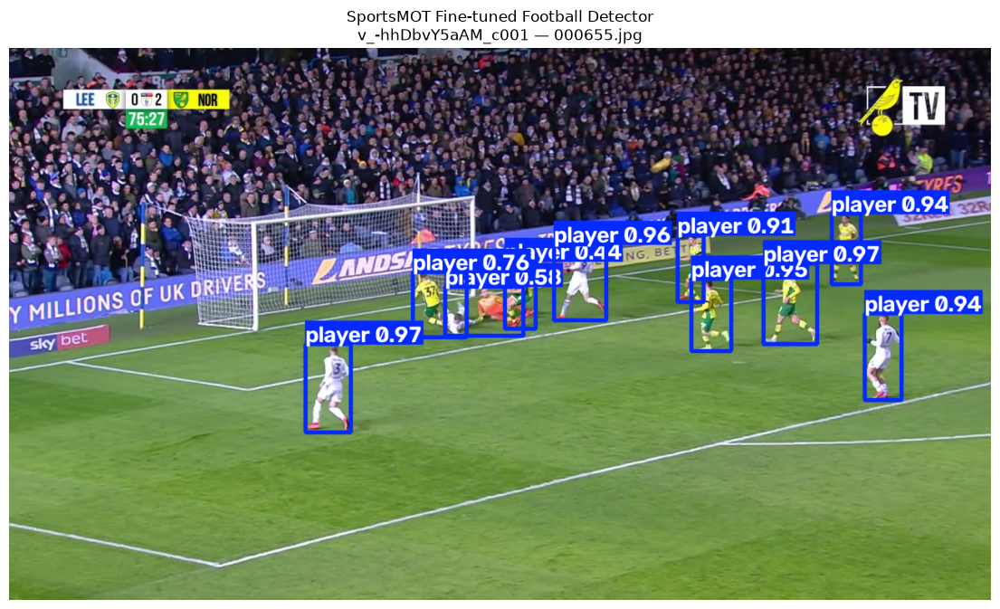

In [54]:
annotated = result.plot()

annotated_rgb = cv2.cvtColor(
    annotated,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(14, 8))
plt.imshow(annotated_rgb)

plt.title(
    f"SportsMOT Fine-tuned Football Detector\n"
    f"{test_item['sequence']} — {test_frame.name}"
)

plt.axis("off")
plt.show()

In [55]:
all_results = []

for i, item in enumerate(test_samples, start=1):

    frame_path = item["frame_path"]

    start_time = time.perf_counter()

    result = finetuned_model.predict(
        source=str(frame_path),
        conf=0.25,
        imgsz=1280,
        device=0 if torch.cuda.is_available() else "cpu",
        verbose=False
    )[0]

    elapsed = time.perf_counter() - start_time

    if result.boxes is not None and len(result.boxes) > 0:

        confidences = (
            result.boxes.conf
            .cpu()
            .numpy()
        )

        detection_count = len(confidences)

        avg_conf = float(np.mean(confidences))
        median_conf = float(np.median(confidences))
        max_conf = float(np.max(confidences))
        min_conf = float(np.min(confidences))

    else:

        detection_count = 0
        avg_conf = 0.0
        median_conf = 0.0
        max_conf = 0.0
        min_conf = 0.0

    all_results.append({
        "sequence": item["sequence"],
        "frame": frame_path.name,
        "frame_path": str(frame_path),
        "detections": detection_count,
        "avg_confidence": avg_conf,
        "median_confidence": median_conf,
        "max_confidence": max_conf,
        "min_confidence": min_conf,
        "inference_time_sec": elapsed
    })

    if i % 25 == 0:
        print(f"Processed {i}/{len(test_samples)} frames")

Processed 25/250 frames
Processed 50/250 frames
Processed 75/250 frames
Processed 100/250 frames
Processed 125/250 frames
Processed 150/250 frames
Processed 175/250 frames
Processed 200/250 frames
Processed 225/250 frames
Processed 250/250 frames


In [56]:
test_results_df = pd.DataFrame(all_results)

test_results_df.head()

,sequence,frame,frame_path,detections,avg_confidence,median_confidence,max_confidence,min_confidence,inference_time_sec
0,v_-hhDbvY5aAM_c001,000655.jpg,/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...,10,0.841927,0.943467,0.970575,0.439260,0.295894
1,v_-hhDbvY5aAM_c001,000115.jpg,/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...,14,0.893578,0.938671,0.964790,0.556506,0.121513
2,v_-hhDbvY5aAM_c001,000026.jpg,/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...,7,0.937907,0.949463,0.963633,0.854718,0.155199
3,v_-hhDbvY5aAM_c001,000282.jpg,/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...,15,0.885148,0.931761,0.960966,0.607305,0.146382
4,v_-hhDbvY5aAM_c001,000251.jpg,/mnt/d/My Projects/AthletiQ/AthletiQ/datasets/...,15,0.900657,0.945393,0.957169,0.529001,0.100322


In [57]:
print("========== UNSEEN FOOTBALL TEST ==========")

print("Frames evaluated:",
      len(test_results_df))

print(
    "Average detections/frame:",
    test_results_df["detections"].mean()
)

print(
    "Median detections/frame:",
    test_results_df["detections"].median()
)

print(
    "Average confidence:",
    test_results_df["avg_confidence"].mean()
)

print(
    "Average inference time:",
    test_results_df["inference_time_sec"].mean()
)

========== UNSEEN FOOTBALL TEST ==========
Frames evaluated: 250
Average detections/frame: 13.66
Median detections/frame: 14.0
Average confidence: 0.8722631502151489
Average inference time: 0.12264594316804141


In [58]:
zero_detection_frames = test_results_df[
    test_results_df["detections"] == 0
].copy()

print(
    "Frames with zero detections:",
    len(zero_detection_frames)
)

zero_detection_frames.head(20)

Frames with zero detections: 0


,sequence,frame,frame_path,detections,avg_confidence,median_confidence,max_confidence,min_confidence,inference_time_sec


In [59]:
low_detection_frames = test_results_df[
    test_results_df["detections"] <= 3
].copy()

print(
    "Frames with <= 3 detections:",
    len(low_detection_frames)
)

Frames with <= 3 detections: 3


In [60]:
low_confidence_frames = test_results_df[
    (test_results_df["detections"] > 0) &
    (test_results_df["avg_confidence"] < 0.50)
].copy()

print(
    "Frames with average confidence < 0.50:",
    len(low_confidence_frames)
)

Frames with average confidence < 0.50: 0


In [61]:
sequence_summary = (
    test_results_df
    .groupby("sequence")
    .agg(
        frames=("frame", "count"),
        avg_detections=("detections", "mean"),
        median_detections=("detections", "median"),
        avg_confidence=("avg_confidence", "mean"),
        zero_detection_frames=("detections", lambda x: (x == 0).sum())
    )
    .reset_index()
)

sequence_summary = sequence_summary.sort_values(
    "avg_confidence"
)

sequence_summary.head(10)

,sequence,frames,avg_detections,median_detections,avg_confidence,zero_detection_frames
48,v_iF9bKPWdZlc_c001,5,9.0,7.0,0.793802,0
49,v_iF9bKPWdZlc_c003,5,8.8,8.0,0.809598,0
22,v_1UDUODIBSsc_c113,5,15.8,17.0,0.812587,0
47,v_foGDoBblREI_c008,5,8.2,6.0,0.813414,0
46,v_foGDoBblREI_c002,5,14.6,16.0,0.820668,0
5,v_-hhDbvY5aAM_c008,5,15.4,17.0,0.835070,0
13,v_1UDUODIBSsc_c015,5,16.4,17.0,0.836987,0
27,v_1UDUODIBSsc_c609,5,16.6,17.0,0.842257,0
20,v_1UDUODIBSsc_c103,5,14.8,16.0,0.843826,0
25,v_1UDUODIBSsc_c603,5,21.0,20.0,0.847455,0


In [62]:
OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "unseen_test"
    / "football"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

test_results_df.to_csv(
    OUTPUT_DIR / "football_unseen_frame_results.csv",
    index=False
)

sequence_summary.to_csv(
    OUTPUT_DIR / "football_unseen_sequence_summary.csv",
    index=False
)

print("Results saved to:")
print(OUTPUT_DIR)

Results saved to:
/mnt/d/My Projects/AthletiQ/AthletiQ/outputs/unseen_test/football


In [63]:
low_detection_frames = test_results_df[
    test_results_df["detections"] <= 3
].copy()

print(low_detection_frames[
    [
        "sequence",
        "frame",
        "detections",
        "avg_confidence",
        "median_confidence"
    ]
].to_string(index=False))

          sequence      frame  detections  avg_confidence  median_confidence
v_2ChiYdg5bxI_c120 000258.jpg           3        0.934801           0.925134
v_2ChiYdg5bxI_c120 000263.jpg           3        0.917493           0.942753
v_2ChiYdg5bxI_c600 000022.jpg           2        0.938630           0.938630


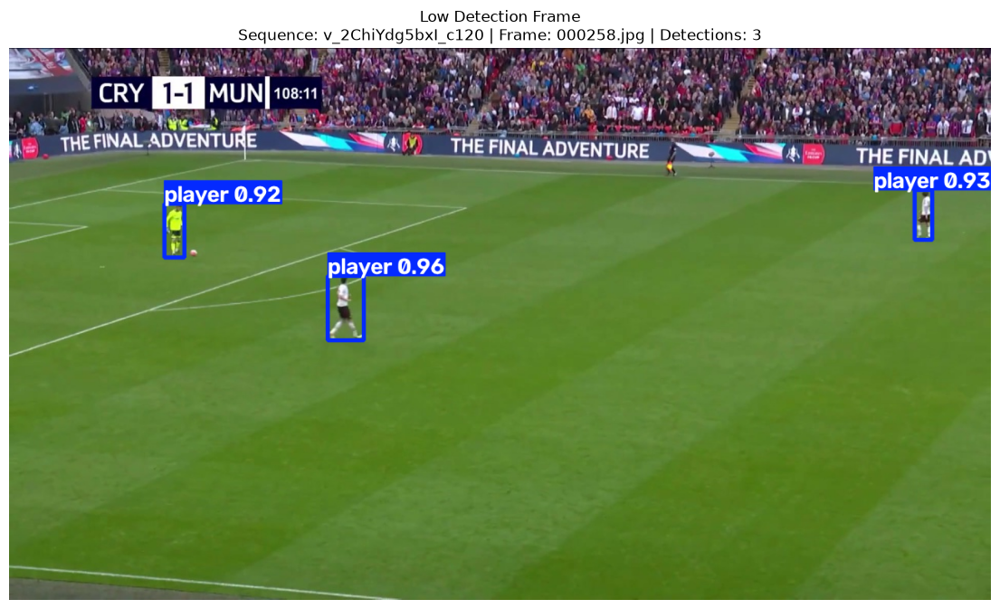

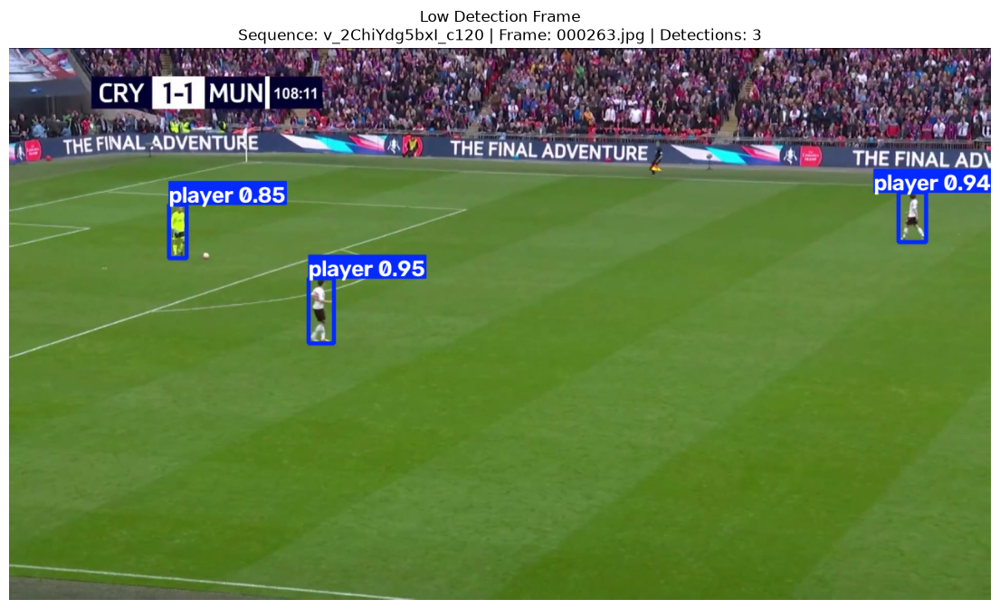

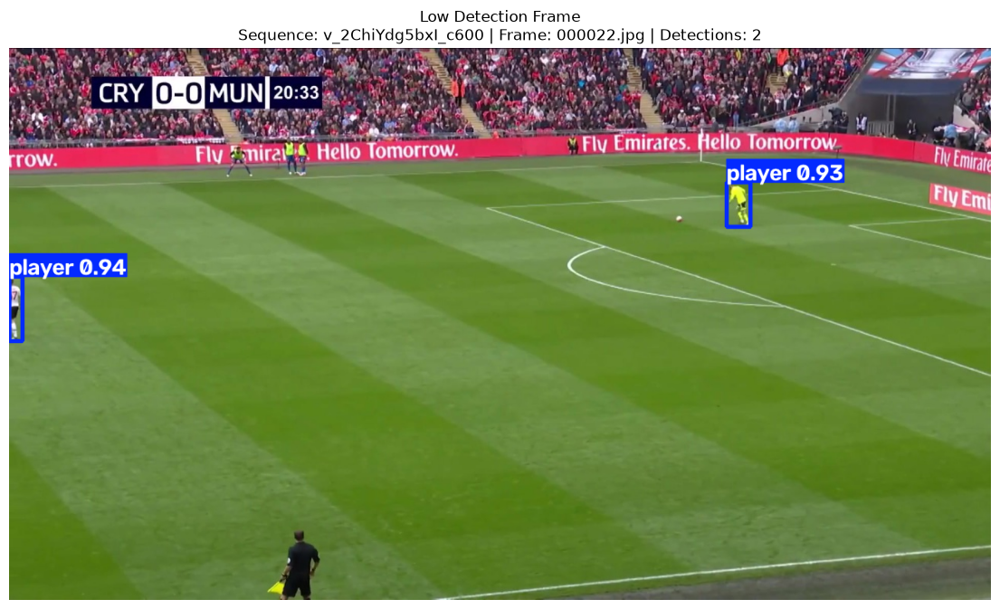

In [64]:
for _, row in low_detection_frames.iterrows():

    frame_path = Path(row["frame_path"])

    result = finetuned_model.predict(
        source=str(frame_path),
        conf=0.25,
        imgsz=1280,
        device=0 if torch.cuda.is_available() else "cpu",
        verbose=False
    )[0]

    annotated = result.plot()

    annotated_rgb = cv2.cvtColor(
        annotated,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(14, 8))

    plt.imshow(annotated_rgb)

    plt.title(
        f"Low Detection Frame\n"
        f"Sequence: {row['sequence']} | "
        f"Frame: {row['frame']} | "
        f"Detections: {row['detections']}"
    )

    plt.axis("off")
    plt.show()

In [65]:
from pathlib import Path
import shutil
import json
from datetime import datetime

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

MODEL_DIR = PROJECT_ROOT / "ai-engine" / "models"

SOURCE_MODEL = MODEL_DIR / "yolov26m-sportsmot-football.pt"
FINAL_MODEL = MODEL_DIR / "football_player_detector.pt"

assert SOURCE_MODEL.exists(), f"Source model not found: {SOURCE_MODEL}"

# Copy instead of rename so the original checkpoint remains preserved
shutil.copy2(
    SOURCE_MODEL,
    FINAL_MODEL
)

print("Football player detector finalized.")
print()
print("Source :", SOURCE_MODEL)
print("Final  :", FINAL_MODEL)
print("Size   :", f"{FINAL_MODEL.stat().st_size / (1024**2):.2f} MB")

Football player detector finalized.

Source : /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/yolov26m-sportsmot-football.pt
Final  : /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/football_player_detector.pt
Size   : 42.04 MB


In [66]:
from ultralytics import YOLO

football_player_detector = YOLO(
    str(FINAL_MODEL)
)

print("Final model loaded successfully.")
print("Classes:", football_player_detector.names)

Final model loaded successfully.
Classes: {0: 'player'}


In [67]:
final_test_frame = test_samples[0]["frame_path"]

final_result = football_player_detector.predict(
    source=str(final_test_frame),
    conf=0.25,
    imgsz=1280,
    device=0 if torch.cuda.is_available() else "cpu",
    verbose=False
)[0]

print("Test frame :", final_test_frame)
print("Detections :", len(final_result.boxes))

Test frame : /mnt/d/My Projects/AthletiQ/AthletiQ/datasets/football/benchmarks/sportsmot/extracted/test/v_-hhDbvY5aAM_c001/img1/000655.jpg
Detections : 10


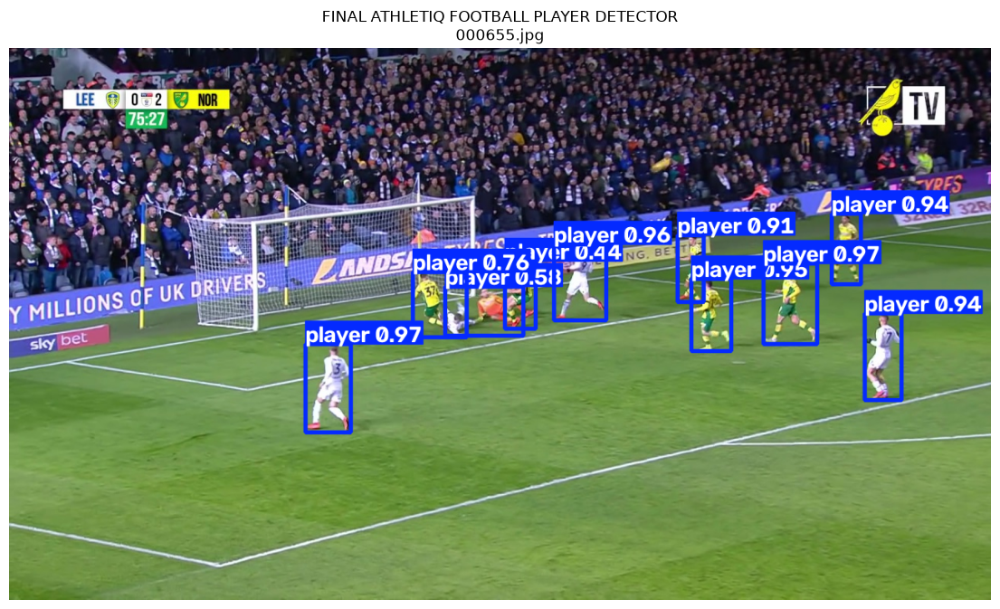

In [69]:
annotated = final_result.plot()

annotated_rgb = cv2.cvtColor(
    annotated,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(14, 8))
plt.imshow(annotated_rgb)
plt.title(
    f"FINAL ATHLETIQ FOOTBALL PLAYER DETECTOR\n"
    f"{final_test_frame.name}"
)
plt.axis("off")
plt.show()

In [71]:
MODEL_MANIFEST = {
    "model_name": "AthletiQ Football Player Detector",
    "model_type": "YOLO",
    "checkpoint": "football_player_detector.pt",
    "source_checkpoint": "yolov26m-sportsmot-football.pt",
    "task": "player_detection",
    "sport": "football",
    "classes": {
        "0": "player"
    },

    "training_dataset": "SportsMOT Football",
    "training_type": "SportsMOT-specific fine-tuning",

    "validation_metrics": {
        "precision": 0.9396,
        "recall": 0.9416,
        "mAP50": 0.9664,
        "mAP50_95": 0.8237
    },

    "unseen_test": {
        "dataset": "SportsMOT Football Test",
        "sequences": 50,
        "sampled_frames": 250,
        "average_detections_per_frame": 13.66,
        "median_detections_per_frame": 14.0,
        "average_confidence": 0.872263,
        "zero_detection_frames": 0,
        "low_detection_frames_leq_3": 3
    },

    "inference": {
        "confidence_threshold": 0.25,
        "image_size": 1280
    },

    "status": "FINAL_FOOTBALL_PLAYER_DETECTOR",
    "finalized_on": datetime.now().isoformat()
}

MANIFEST_PATH = MODEL_DIR / "football_player_detector.json"

with open(MANIFEST_PATH, "w") as f:
    json.dump(
        MODEL_MANIFEST,
        f,
        indent=4
    )

print("Manifest saved:")
print(MANIFEST_PATH)

Manifest saved:
/mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/models/football_player_detector.json


In [73]:
print("========== FINAL FOOTBALL MODEL ==========")

print("Model exists   :", FINAL_MODEL.exists())
print("Manifest exists:", MANIFEST_PATH.exists())

if FINAL_MODEL.exists():
    print(
        "Model size     :",
        f"{FINAL_MODEL.stat().st_size / (1024**2):.2f} MB"
    )

print("\nModel:", FINAL_MODEL.name)
print("Manifest:", MANIFEST_PATH.name)

========== FINAL FOOTBALL MODEL ==========
Model exists   : True
Manifest exists: True
Model size     : 42.04 MB

Model: football_player_detector.pt
Manifest: football_player_detector.json


In [74]:
GITIGNORE = PROJECT_ROOT / ".gitignore"

print(GITIGNORE.read_text())

# Python
__pycache__/
*.py[cod]
*.so
.pytest_cache/
.mypy_cache/
.ruff_cache/

# Virtual environments
.venv/
venv/
env/

# Jupyter
.ipynb_checkpoints/

# Environment variables / secrets
.env
.env.*
!.env.example

# Model weights
*.pt
*.pth
*.onnx
*.engine

# Datasets
datasets/*/raw/*
datasets/*/frames/*
datasets/*/processed/*
datasets/*/annotations/*

# Generated outputs
outputs/*
experiments/*

# Logs
*.log

# OS
.DS_Store
Thumbs.db

# IDE
.vscode/
.idea/
EOF
# ==============================
# Datasets
# ==============================

datasets/
